# CSIS 4495 002 Applied Research Project
- Student Name: Liqin Shi
- Student ID: 300431612

In [1]:
import pandas as pd
import matplotlib.pyplot as plt




In [2]:
df = pd.read_sas("../LocalData/LLCP2025.XPT", format="xport")

In [3]:
# Load the official CDC BRFSS 2025 data
df = pd.read_csv("../LocalData/BRFSS2025.csv")

# Basic dataset information
print("Shape:", df.shape)
display(df.head())

Shape: (356158, 283)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [4]:
# Display all column names
print(df.columns.tolist())

['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX4', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX4', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'BPHIGH6', 'BPMEDS1', 'CHOLCHK3', 'TOLDHI3', 'CHOLMED3', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNC1', 'CHCOCNC1', 'CHCCOPD3', 'ADDEPEV3', 'CHCKDNY2', 'HAVARTH4', 'DIABETE4', 'DIABAGE4', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL4', 'NUMPHON4', 'CPDEMO1C', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME3', 'PREGNANT', 'WEIGHT2', 'HEIGHT3', 'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SLEPTIM1', 'SMOKE100', 'SMOKDAY2', 'USENOW3', 'ECIGNOW3', 'ALCDAY4', 'AVEDRNK4', 'DRNK3GE5', 'MAXDRNKS', 'FLUSHOT7', 'FLSHTMY3', 'PNEUVAC4', 'TETANUS1

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)

display(missing.head(30))

ICFQSTVR    356158
COLGHOUS    356153
CSRVCTL2    355628
CCLGHOUS    355147
CSRVINST    354093
HPVADSHT    353642
NOBCUSE9    353591
CSRVCLIN    353410
CSRVDEIN    353406
CSRVINSR    353403
CSRVRTRN    353396
CSRVSUM     353392
CSRVDOC1    353388
CASTHNO2    353217
NUMPHON4    352346
USEMRJN4    352330
PSASUGS1    351945
PCPSARS2    351938
PSATIME1    351933
MENTECIG    351664
CSRVTRT3    351426
LOADULK2    350566
CSRVPAIN    350483
CNCRTYP2    348970
CNCRAGE     348960
PCSTALK2    348844
PSATEST1    348802
CNCRDIFF    348772
MENTCIGS    348324
MARJOTHR    347202
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 356158 entries, 0 to 356157
Columns: 283 entries, _STATE to _AIDTST4
dtypes: float64(278), object(5)
memory usage: 769.0+ MB


In [7]:
missing = df.isnull().sum().sort_values(ascending=False)

display(missing)

ICFQSTVR    356158
COLGHOUS    356153
CSRVCTL2    355628
CCLGHOUS    355147
CSRVINST    354093
             ...  
_AGE65YR         0
_AGE80           0
_AGE_G           0
_RFBMI5          0
_STATE           0
Length: 283, dtype: int64

In [8]:
# Calculate missing percentage for each column
missing_pct = df.isnull().mean() * 100

# Group columns by missing percentage
print("Total columns:", len(df.columns))
print("No missing values:", (missing_pct == 0).sum())
print("0–10% missing:", ((missing_pct > 0) & (missing_pct <= 10)).sum())
print("10–30% missing:", ((missing_pct > 10) & (missing_pct <= 30)).sum())
print("30–50% missing:", ((missing_pct > 30) & (missing_pct <= 50)).sum())
print("50–80% missing:", ((missing_pct > 50) & (missing_pct <= 80)).sum())
print("80–100% missing:", ((missing_pct > 80) & (missing_pct <= 100)).sum())

Total columns: 283
No missing values: 59
0–10% missing: 62
10–30% missing: 25
30–50% missing: 1
50–80% missing: 28
80–100% missing: 108


## 1 Data Cleaning

In [9]:
# Search for candidate variables related to diabetes risk factors

keywords = [
    "DIAB", "AGE", "SEX", "RACE", "EDU", "INCOME",
    "BMI", "BPHIGH", "CHOL", "CVD",
    "STROKE", "EXER", "PHYS", "SMOK",
    "ALCO", "FRUIT", "VEG",
    "GENHLTH", "MENTHLTH", "PHYSHLTH",
    "DIFF", "HLTHPLN", "COST", "CHECK"
]

for keyword in keywords:
    matches = [col for col in df.columns if keyword in col.upper()]
    print(f"\n{keyword}:")
    print(matches)


DIAB:
['DIABETE4', 'DIABAGE4', 'PDIABTS1', 'PREDIAB2', 'DIABTYPE', 'DIABEYE1', 'DIABEDU1']

AGE:
['DIABAGE4', 'CNCRAGE', 'CAGEG', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G']

SEX:
['LANDSEX4', 'CELLSEX4', 'SEXVAR', 'ACEHVSEX', 'HADSEX', '_SEX']

RACE:
['_IMPRACE', '_CRACE1', '_MRACE1', '_RACE', '_RACEG21', '_RACEGR3', '_RACEPRV']

EDU:
['EDUCA', 'DIABEDU1', 'ARTHEDU', '_EDUCAG']

INCOME:
['INCOME3']

BMI:
['_BMI5', '_BMI5CAT', '_RFBMI5']

BPHIGH:
['BPHIGH6']

CHOL:
['CHOLCHK3', 'CHOLMED3', '_CHOLCH3', '_RFCHOL3']

CVD:
['CVDINFR4', 'CVDCRHD4', 'CVDSTRK3']

STROKE:
[]

EXER:
['EXERANY2', 'ARTHEXER']

PHYS:
['PHYSHLTH', '_PHYS14D']

SMOK:
['SMOKE100', 'SMOKDAY2', 'MARJSMOK', '_SMOKER3', '_RFSMOK3']

ALCO:
['_DUALCOR']

FRUIT:
['FRUIT2', 'FRUITJU2', '_FRUITE1']

VEG:
['VEGETAB2', 'VEGEDA2_', '_MISVEG1', '_VEGRES1', '_VEGESU1', '_VEGLT1A', '_VEG23A', '_VEGETE1']

GENHLTH:
['GENHLTH']

MENTHLTH:
['MENTHLTH']

PHYSHLTH:
['PHYSHLTH']

DIFF:
['DIFFWALK', 'DIFFDRES', 'DIFFALON', 'CNCRDIFF']

H

## Initial Feature Selection – BRFSS 2025
Candidate variables were reviewed using the CDC BRFSS 2025 codebook. Variables were selected based on their potential relevance to diabetes and prediabetes, while retaining additional candidates for later exploratory analysis and feature selection. Final features will be determined after data cleaning, EDA, missing-value analysis, and feature evaluation.

In [10]:
# Check the original distribution of the diabetes target variable
df['DIABETE4'].value_counts(dropna=False).sort_index()

DIABETE4
1.0     51827
2.0      2671
3.0    290712
4.0     10166
7.0       580
9.0       196
NaN         6
Name: count, dtype: int64

In [11]:
# Check percentages
df['DIABETE4'].value_counts(
    dropna=False,
    normalize=True
).sort_index() * 100

DIABETE4
1.0    14.551688
2.0     0.749948
3.0    81.624448
4.0     2.854351
7.0     0.162849
9.0     0.055032
NaN     0.001685
Name: proportion, dtype: float64

In [12]:
# Create a clean three-class diabetes target variable
diabetes_map = {
    1: 'Diabetes',
    3: 'No Diabetes',
    4: 'Prediabetes'
}

df['Diabetes_Status'] = df['DIABETE4'].map(diabetes_map)

# Check the cleaned target distribution
df['Diabetes_Status'].value_counts(dropna=False)

Diabetes_Status
No Diabetes    290712
Diabetes        51827
Prediabetes     10166
NaN              3453
Name: count, dtype: int64

In [13]:
# Keep the CDC age variable for modeling
df['Age'] = df['_AGE80']

# Main age groups aligned with the National Diabetes Statistics Report.
# This grouping allows direct comparison with the national report:
# 18–44, 45–64, and 65 years or older.
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 44, 64, float('inf')],
    labels=['18-44', '45-64', '65+']
)

# Create more detailed age groups for exploratory analysis.
# Broader groups are used below age 50 for concise comparison,
# while 5-year groups from age 50 onward provide more detail.
df['Age_Group_Detailed'] = pd.cut(
    df['Age'],
    bins=[17, 39, 49, 54, 59, 64, 69, 74, 79, float('inf')],
    labels=[
        '18-39',
        '40-49',
        '50-54',
        '55-59',
        '60-64',
        '65-69',
        '70-74',
        '75-79',
        '80+'
    ]
)

# Check the distributions
print("National report age groups:")
print(df['Age_Group'].value_counts(dropna=False).sort_index())

print("\nDetailed age groups:")
print(df['Age_Group_Detailed'].value_counts(dropna=False).sort_index())

National report age groups:
Age_Group
18-44    105537
45-64    108396
65+      142225
Name: count, dtype: int64

Detailed age groups:
Age_Group_Detailed
18-39    82218
40-49    45997
50-54    25035
55-59    27901
60-64    32782
65-69    37194
70-74    36613
75-79    31526
80+      36892
Name: count, dtype: int64


In [14]:
# Check the original distribution of sex
print(df['_SEX'].value_counts(dropna=False).sort_index())

print("\nPercentage:")
print(
    df['_SEX']
    .value_counts(normalize=True, dropna=False)
    .sort_index() * 100
)

_SEX
1.0    168462
2.0    187696
Name: count, dtype: int64

Percentage:
_SEX
1.0    47.299794
2.0    52.700206
Name: proportion, dtype: float64


In [15]:
# Create a readable sex variable
sex_map = {
    1: 'Male',
    2: 'Female'
}

df['Sex'] = df['_SEX'].map(sex_map)

# Check the cleaned distribution
print(df['Sex'].value_counts(dropna=False))

print("\nPercentage:")
print(
    df['Sex']
    .value_counts(normalize=True, dropna=False) * 100
)

Sex
Female    187696
Male      168462
Name: count, dtype: int64

Percentage:
Sex
Female    52.700206
Male      47.299794
Name: proportion, dtype: float64


In [16]:
# Compare diabetes status by sex
sex_diabetes = pd.crosstab(
    df['Sex'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(sex_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Sex,,,
Female,14.14,82.81,3.05
Male,15.31,82.00,2.70


### conclusion: In the BRFSS 2025 sample, males had a slightly higher proportion of diabetes (15.31%) than females (14.14%), while females had a slightly higher proportion of prediabetes (3.05%) than males (2.70%).

In [17]:
# Compare diabetes status by National Report age groups
age_diabetes_national = pd.crosstab(
    df['Age_Group'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(age_diabetes_national.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Age_Group,,,
18-44,3.65,94.72,1.63
45-64,16.01,80.64,3.34
65+,21.81,74.75,3.45


In [18]:
# Compare diabetes status by detailed age groups
age_diabetes_detailed = pd.crosstab(
    df['Age_Group_Detailed'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(age_diabetes_detailed.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Age_Group_Detailed,,,
18-39,2.63,95.92,1.45
40-49,8.80,88.62,2.57
50-54,14.37,82.37,3.26
55-59,17.82,78.69,3.49
60-64,19.58,76.81,3.61
65-69,21.52,74.80,3.68
70-74,22.45,74.14,3.41
75-79,23.64,72.88,3.48
80+,19.89,76.89,3.22


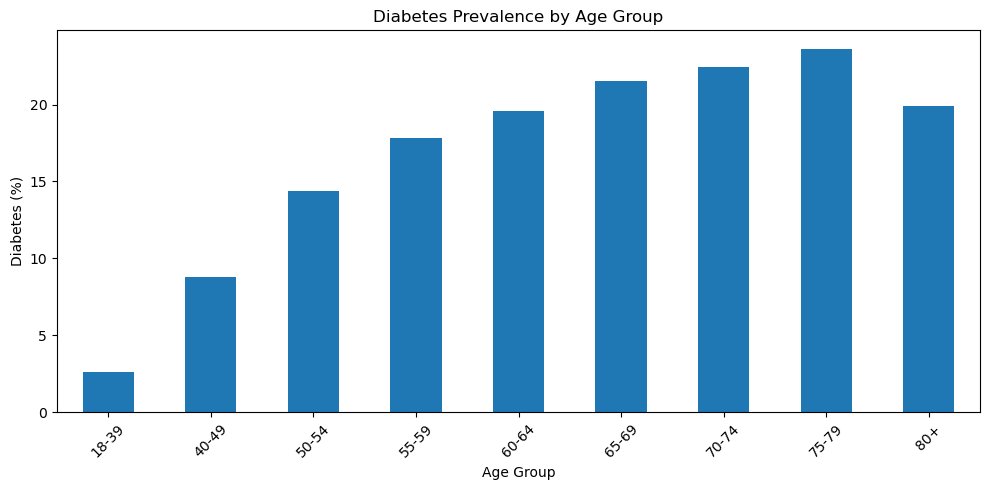

In [19]:

# Extract diabetes percentage for each detailed age group
diabetes_by_age = age_diabetes_detailed['Diabetes']

plt.figure(figsize=(10, 5))

diabetes_by_age.plot(kind='bar')

plt.title('Diabetes Prevalence by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Diabetes (%)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Conclusion: Age and Diabetes Status

The analysis shows a clear relationship between age and diabetes prevalence in the BRFSS 2025 sample. Diabetes prevalence increased from 3.65% among adults aged 18–44 to 16.01% among those aged 45–64 and 21.81% among those aged 65 and older.

The more detailed age-group analysis showed a similar pattern, with diabetes prevalence increasing steadily from 2.63% among adults aged 18–39 to a peak of 23.64% among those aged 75–79. The prevalence then decreased to 19.89% among respondents aged 80 and older.

Overall, these results suggest that age is an important factor associated with diabetes status in this sample. However, the analysis is descriptive, so other factors may also contribute to the observed differences across age groups.